# A10 — Learning Kinect 2D from PoseNet 2D with PyTorch and MLflow

This notebook evaluates deep learning models for predicting Kinect 2D joint coordinates from PoseNet 2D joint coordinates.

Main task:
- Input: 13 joints × 2 PoseNet coordinates = 26 features
- Target: 13 joints × 2 Kinect coordinates = 26 features

This notebook:
- loads PoseNet CSV files generated from the videos
- loads Kinect CSV files
- merges matching sequences by frame number
- standardizes both inputs and targets
- builds fixed-length frame windows
- trains PyTorch models on GPU if available
- uses grouped k-fold cross validation
- applies early stopping
- logs results to MLflow
- saves the final champion model and scalers

## Imports and shared configuration

In [90]:
from pathlib import Path
import os
import random
import warnings
import copy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv


warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Shared experiment settings
SEQ_LEN = 20
STRIDE = 1
N_SPLITS = 10
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 80 #reduced for now
PATIENCE = 12 #reduced for now
LEARNING_RATE = 1e-3

LOSS_NAME = "mse"
DEFAULT_OPTIMIZER = "adam"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

POSENET_DIR = Path("../../data/raw/posenet_generated")
KINECT_DIR = Path("../../data/raw/kinect_good_preprocessed")

output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

JOINTS = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

INPUT_FEATURES = [f"pn_{j}_{axis}" for j in JOINTS for axis in ["x", "y"]]
TARGET_FEATURES = [f"k_{j}_{axis}" for j in JOINTS for axis in ["x", "y"]]

FRAME_COL_CANDIDATES = ["FrameNo", "frame", "frame_no", "Frame", "frameno"]
SEQUENCE_COL_CANDIDATES = ["sequence_id", "SequenceId", "movement_id", "MovementId", "id", "ID"]

TARGET_UNIT = "meters"
CM_CONVERSION = 100.0 if TARGET_UNIT == "meters" else 1.0

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("POSENET_DIR:", POSENET_DIR)
print("KINECT_DIR:", KINECT_DIR)

DEVICE: cuda
GPU: NVIDIA GeForce RTX 2070
POSENET_DIR: ..\..\data\raw\posenet_generated
KINECT_DIR: ..\..\data\raw\kinect_good_preprocessed


## MLFlow setup

In [91]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A10_2D_posenet"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A10_2D_posenet


## Helper functions

In [92]:
def read_table_file(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\t")
    if suffix == ".txt":
        try:
            df = pd.read_csv(path)
            if df.shape[1] > 1:
                return df
        except Exception:
            pass
        return pd.read_csv(path, delim_whitespace=True)
    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Unsupported file type: {path}")


def find_frame_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in FRAME_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def find_sequence_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in SEQUENCE_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def standardize_joint_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    rename_map = {}
    for col in df.columns:
        normalized = col.strip().lower().replace(" ", "_").replace("-", "_")
        rename_map[col] = normalized
    return df.rename(columns=rename_map)


def extract_base_id(file_path: Path) -> str:
    name = file_path.stem
    name = name.replace("_kinect", "")
    name = name.replace("_posenet", "")
    name = name.replace("_pose", "")
    return name


def to_cm(value):
    return value * CM_CONVERSION

### Check data files exist

In [93]:
posenet_files = sorted(POSENET_DIR.glob("*.csv"))
kinect_files = sorted(KINECT_DIR.glob("*.csv"))

print("PoseNet csv count:", len(posenet_files))
print("Kinect csv count:", len(kinect_files))

if len(posenet_files) == 0:
    raise FileNotFoundError(
        f"No PoseNet CSV files found in {POSENET_DIR}.\n"
        "Generate PoseNet CSVs from the videos first, then rerun A10."
    )

if len(kinect_files) == 0:
    raise FileNotFoundError(
        f"No Kinect CSV files found in {KINECT_DIR}."
    )

PoseNet csv count: 181
Kinect csv count: 179


### Load nad merge posenet + kinect

In [94]:
def load_and_merge_posenet_kinect(posenet_dir: Path, kinect_dir: Path) -> pd.DataFrame:
    posenet_files = sorted(posenet_dir.glob("*.csv"))
    kinect_files = sorted(kinect_dir.glob("*.csv"))

    posenet_map = {extract_base_id(p): p for p in posenet_files}
    kinect_map = {extract_base_id(p): p for p in kinect_files}

    common_ids = sorted(set(posenet_map.keys()) & set(kinect_map.keys()))
    missing_in_posenet = sorted(set(kinect_map.keys()) - set(posenet_map.keys()))
    missing_in_kinect = sorted(set(posenet_map.keys()) - set(kinect_map.keys()))

    print("Matched sequences:", len(common_ids))
    print("Missing in PoseNet:", missing_in_posenet[:10])
    print("Missing in Kinect:", missing_in_kinect[:10])

    if not common_ids:
        raise ValueError("No matching PoseNet/Kinect files found.")

    merged_dfs = []

    for seq_id in common_ids:
        pn_path = posenet_map[seq_id]
        k_path = kinect_map[seq_id]

        pn_df = standardize_joint_column_names(read_table_file(pn_path))
        k_df = standardize_joint_column_names(read_table_file(k_path))

        pn_seq_col = find_sequence_col(pn_df)
        if pn_seq_col is None:
            pn_df["sequence_id"] = seq_id
        elif pn_seq_col != "sequence_id":
            pn_df = pn_df.rename(columns={pn_seq_col: "sequence_id"})

        pn_frame_col = find_frame_col(pn_df)
        if pn_frame_col is None:
            pn_df["frameno"] = np.arange(len(pn_df))
        elif pn_frame_col != "frameno":
            pn_df = pn_df.rename(columns={pn_frame_col: "frameno"})

        k_seq_col = find_sequence_col(k_df)
        if k_seq_col is None:
            k_df["sequence_id"] = seq_id
        elif k_seq_col != "sequence_id":
            k_df = k_df.rename(columns={k_seq_col: "sequence_id"})

        k_frame_col = find_frame_col(k_df)
        if k_frame_col is None:
            k_df["frameno"] = np.arange(len(k_df))
        elif k_frame_col != "frameno":
            k_df = k_df.rename(columns={k_frame_col: "frameno"})

        pn_rename = {}
        for joint in JOINTS:
            for axis in ["x", "y"]:
                src = f"{joint}_{axis}"
                dst = f"pn_{joint}_{axis}"
                if src in pn_df.columns:
                    pn_rename[src] = dst
        pn_df = pn_df.rename(columns=pn_rename)

        k_rename = {}
        for joint in JOINTS:
            for axis in ["x", "y", "z"]:
                src = f"{joint}_{axis}"
                dst = f"k_{joint}_{axis}"
                if src in k_df.columns:
                    k_rename[src] = dst
        k_df = k_df.rename(columns=k_rename)

        pn_keep = ["sequence_id", "frameno"] + [c for c in INPUT_FEATURES if c in pn_df.columns]
        k_keep = ["sequence_id", "frameno"] + [c for c in TARGET_FEATURES if c in k_df.columns]

        pn_df = pn_df[pn_keep].copy()
        k_df = k_df[k_keep].copy()

        merged = pd.merge(pn_df, k_df, on=["sequence_id", "frameno"], how="inner")
        merged_dfs.append(merged)

    full_df = pd.concat(merged_dfs, ignore_index=True)
    full_df = full_df.sort_values(["sequence_id", "frameno"]).reset_index(drop=True)
    return full_df


df = load_and_merge_posenet_kinect(POSENET_DIR, KINECT_DIR)

print("Shape:", df.shape)
print("Columns:", len(df.columns))
display(df.head())

missing_inputs = [c for c in INPUT_FEATURES if c not in df.columns]
missing_targets = [c for c in TARGET_FEATURES if c not in df.columns]

print("Missing input columns:", missing_inputs)
print("Missing target columns:", missing_targets)

assert not missing_inputs, "Missing PoseNet input columns."
assert not missing_targets, "Missing Kinect target columns."

Matched sequences: 179
Missing in PoseNet: []
Missing in Kinect: ['A60', 'posenet_generation_summary']
Shape: (24005, 54)
Columns: 54


,sequence_id,frameno,pn_head_x,pn_head_y,pn_left_shoulder_x,pn_left_shoulder_y,pn_left_elbow_x,pn_left_elbow_y,pn_right_shoulder_x,pn_right_shoulder_y,...,k_right_hip_x,k_right_hip_y,k_left_knee_x,k_left_knee_y,k_right_knee_x,k_right_knee_y,k_left_foot_x,k_left_foot_y,k_right_foot_x,k_right_foot_y
0,A1,68,991.198604,260.810939,1050.207223,350.621848,1103.074503,287.405884,937.012138,336.460121,...,0.070990,0.050062,-0.12024,-0.31613,0.10949,-0.32352,-0.13160,-0.73613,0.13035,-0.74466
1,A1,69,991.070028,261.879878,1050.433990,350.473674,1102.743606,291.447918,937.913300,337.325910,...,0.071481,0.049983,-0.11961,-0.31636,0.11010,-0.32371,-0.13135,-0.73634,0.13078,-0.74484
2,A1,70,991.292346,261.123256,1050.139370,350.467175,1103.530488,288.592060,938.931798,338.126651,...,0.072057,0.049890,-0.11884,-0.31667,0.11070,-0.32399,-0.13110,-0.73665,0.13120,-0.74506
3,A1,71,991.415916,261.879359,1051.265302,349.772855,1103.656437,286.813590,936.743363,338.002401,...,0.072543,0.049759,-0.11805,-0.31707,0.11128,-0.32436,-0.13102,-0.73711,0.13164,-0.74529
4,A1,72,987.703924,266.026904,1049.559114,344.481013,1115.848482,328.638712,928.860345,333.770843,...,0.072987,0.049613,-0.11727,-0.31750,0.11181,-0.32480,-0.13096,-0.73750,0.13212,-0.74567


Missing input columns: []
Missing target columns: []


### Hip-centered normalization

In [95]:
USE_HIP_CENTER_NORMALIZATION = True
USE_TORSO_SCALE_NORMALIZATION = True

def normalize_skeleton_relative_to_body(
    df: pd.DataFrame,
    joint_names,
    input_prefix="pn_",
    target_prefix="k_",
    eps=1e-6,
):
    df = df.copy()

    for prefix in [input_prefix, target_prefix]:
        left_hip_x = f"{prefix}left_hip_x"
        left_hip_y = f"{prefix}left_hip_y"
        right_hip_x = f"{prefix}right_hip_x"
        right_hip_y = f"{prefix}right_hip_y"

        left_shoulder_x = f"{prefix}left_shoulder_x"
        left_shoulder_y = f"{prefix}left_shoulder_y"
        right_shoulder_x = f"{prefix}right_shoulder_x"
        right_shoulder_y = f"{prefix}right_shoulder_y"

        hip_center_x = (df[left_hip_x] + df[right_hip_x]) / 2.0
        hip_center_y = (df[left_hip_y] + df[right_hip_y]) / 2.0

        shoulder_center_x = (df[left_shoulder_x] + df[right_shoulder_x]) / 2.0
        shoulder_center_y = (df[left_shoulder_y] + df[right_shoulder_y]) / 2.0

        torso_length = np.sqrt(
            (shoulder_center_x - hip_center_x) ** 2 +
            (shoulder_center_y - hip_center_y) ** 2
        )
        torso_length = np.where(torso_length < eps, 1.0, torso_length)

        for joint in joint_names:
            x_col = f"{prefix}{joint}_x"
            y_col = f"{prefix}{joint}_y"

            df[x_col] = df[x_col] - hip_center_x
            df[y_col] = df[y_col] - hip_center_y

            if USE_TORSO_SCALE_NORMALIZATION:
                df[x_col] = df[x_col] / torso_length
                df[y_col] = df[y_col] / torso_length

    return df


if USE_HIP_CENTER_NORMALIZATION:
    df = normalize_skeleton_relative_to_body(df, JOINTS, input_prefix="pn_", target_prefix="k_")
    print("Applied hip-centered normalization.")
    print("Applied torso scaling:", USE_TORSO_SCALE_NORMALIZATION)

display(df.head())

Applied hip-centered normalization.
Applied torso scaling: True


,sequence_id,frameno,pn_head_x,pn_head_y,pn_left_shoulder_x,pn_left_shoulder_y,pn_left_elbow_x,pn_left_elbow_y,pn_right_shoulder_x,pn_right_shoulder_y,...,k_right_hip_x,k_right_hip_y,k_left_knee_x,k_left_knee_y,k_right_knee_x,k_right_knee_y,k_left_foot_x,k_left_foot_y,k_right_foot_x,k_right_foot_y
0,A1,68,0.015138,-1.402795,0.302696,-0.965132,0.560327,-1.273194,-0.248921,-1.034145,...,0.142370,-0.007573,-0.244514,-0.748428,0.220261,-0.763379,-0.267497,-1.598144,0.262463,-1.615402
1,A1,69,0.016368,-1.400701,0.306746,-0.967346,0.562617,-1.256070,-0.243648,-1.031658,...,0.142447,-0.007491,-0.244162,-0.748663,0.220580,-0.763533,-0.267913,-1.598351,0.262419,-1.615548
2,A1,70,0.018861,-1.399640,0.302035,-0.969714,0.558954,-1.267459,-0.233100,-1.029097,...,0.142597,-0.007369,-0.243517,-0.748785,0.220758,-0.763591,-0.268314,-1.598249,0.262222,-1.615260
3,A1,71,0.018522,-1.391412,0.304521,-0.971399,0.554880,-1.272260,-0.242739,-1.027646,...,0.142691,-0.007215,-0.242566,-0.748709,0.220992,-0.763445,-0.268783,-1.597762,0.262147,-1.614296
4,A1,72,-0.016710,-1.348958,0.278610,-0.974387,0.595102,-1.050025,-0.297652,-1.025522,...,0.142781,-0.007048,-0.241412,-0.748373,0.221178,-0.763114,-0.269056,-1.596494,0.262191,-1.612992


In [96]:
def interpolate_sequence_columns(df: pd.DataFrame, cols):
    df = df.copy()

    def interp_group(g):
        g = g.sort_values("frameno").copy()
        g[cols] = g[cols].interpolate(method="linear", limit_direction="both")
        g[cols] = g[cols].ffill().bfill()
        return g

    return (
        df.groupby("sequence_id", group_keys=False)
        .apply(interp_group)
        .reset_index(drop=True)
    )

In [97]:
df = interpolate_sequence_columns(df, INPUT_FEATURES + TARGET_FEATURES)

### Build fixed-length sequences

In [98]:
def build_sequences(
    df: pd.DataFrame,
    input_cols,
    target_cols,
    seq_len: int = 20,
    stride: int = 1,
):
    X_list = []
    y_list = []
    seq_ids = []

    clean_df = df.copy()

    for seq_id, group in clean_df.groupby("sequence_id"):
        group = group.sort_values("frameno").reset_index(drop=True)

        x_values = group[input_cols].to_numpy(dtype=np.float32)
        y_values = group[target_cols].to_numpy(dtype=np.float32)

        if len(group) < seq_len:
            continue

        for start in range(0, len(group) - seq_len + 1, stride):
            end = start + seq_len
            X_list.append(x_values[start:end])
            y_list.append(y_values[start:end])
            seq_ids.append(seq_id)

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)
    seq_ids = np.array(seq_ids)

    return X, y, seq_ids


X, y, seq_ids = build_sequences(
    df=df,
    input_cols=INPUT_FEATURES,
    target_cols=TARGET_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("seq_ids shape:", seq_ids.shape)
print("Unique sequences:", len(np.unique(seq_ids)))

X shape: (20604, 20, 26)
y shape: (20604, 20, 26)
seq_ids shape: (20604,)
Unique sequences: 179


### Inspect target scale

In [99]:
xy_summary = df[TARGET_FEATURES].describe().T[["mean", "std", "min", "max"]]
display(xy_summary)

print("TARGET_UNIT =", TARGET_UNIT)
print("CM_CONVERSION =", CM_CONVERSION)

,mean,std,min,max
k_head_x,-0.018345,0.057178,-0.567964,0.321641
k_head_y,1.393060,0.058838,1.140407,1.659589
k_left_shoulder_x,-0.317454,0.054656,-0.866599,-0.017990
k_left_shoulder_y,0.999649,0.020405,0.842925,1.162959
k_left_elbow_x,-0.551666,0.130145,-1.226303,-0.132320
k_left_elbow_y,1.375311,0.136106,0.289610,1.668509
k_right_shoulder_x,0.302059,0.050122,0.012041,0.601426
k_right_shoulder_y,0.998380,0.020101,0.829379,1.156933
k_right_elbow_x,0.547237,0.123178,-0.038582,1.211800
k_right_elbow_y,1.376795,0.131091,0.451062,1.626775


TARGET_UNIT = meters
CM_CONVERSION = 100.0


### Dataset and scaling helpers

In [100]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def fit_scaler_on_training_sequences(X_train):
    scaler = StandardScaler()
    X_train_2d = X_train.reshape(-1, X_train.shape[-1])
    scaler.fit(X_train_2d)
    return scaler


def transform_sequences(X_data, scaler):
    X_2d = X_data.reshape(-1, X_data.shape[-1])
    X_scaled = scaler.transform(X_2d).reshape(X_data.shape).astype(np.float32)
    return X_scaled


def inverse_transform_sequences(X_data, scaler):
    X_2d = X_data.reshape(-1, X_data.shape[-1])
    X_inv = scaler.inverse_transform(X_2d).reshape(X_data.shape).astype(np.float32)
    return X_inv

### Define Deep Learning models

In [101]:
class DensePoseNetToKinectRegressor(nn.Module):
    def __init__(self, seq_len, n_features, n_targets, hidden_units=(256, 128), dropout_rate=0.0):
        super().__init__()
        input_dim = seq_len * n_features
        output_dim = seq_len * n_targets

        layers_list = []
        prev_dim = input_dim

        for units in hidden_units:
            layers_list.append(nn.Linear(prev_dim, units))
            layers_list.append(nn.ReLU())
            if dropout_rate > 0:
                layers_list.append(nn.Dropout(dropout_rate))
            prev_dim = units

        layers_list.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers_list)

        self.seq_len = seq_len
        self.n_targets = n_targets

    def forward(self, x):
        batch_size = x.shape[0]
        x = x.reshape(batch_size, -1)
        out = self.network(x)
        out = out.reshape(batch_size, self.seq_len, self.n_targets)
        return out


class Conv1DPoseNetToKinectRegressor(nn.Module):
    def __init__(self, n_features, n_targets, filters=(64, 128), kernel_size=3, dropout_rate=0.0):
        super().__init__()

        conv_layers = []
        in_channels = n_features

        for f in filters:
            conv_layers.append(nn.Conv1d(in_channels, f, kernel_size=kernel_size, padding="same"))
            conv_layers.append(nn.ReLU())
            if dropout_rate > 0:
                conv_layers.append(nn.Dropout(dropout_rate))
            in_channels = f

        self.feature_extractor = nn.Sequential(*conv_layers)
        self.output_layer = nn.Conv1d(in_channels, n_targets, kernel_size=1)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.feature_extractor(x)
        x = self.output_layer(x)
        x = x.transpose(1, 2)
        return x


class GRUPoseNetToKinectRegressor(nn.Module):
    def __init__(self, n_features, n_targets, hidden_size=128, num_layers=1, dropout_rate=0.0, bidirectional=False):
        super().__init__()
        gru_dropout = dropout_rate if num_layers > 1 else 0.0

        self.gru = nn.GRU(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=gru_dropout,
            bidirectional=bidirectional,
        )

        direction_factor = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout_rate) if dropout_rate > 0 else nn.Identity()
        self.output_layer = nn.Linear(hidden_size * direction_factor, n_targets)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.dropout(out)
        out = self.output_layer(out)
        return out


class LSTMPoseNetToKinectRegressor(nn.Module):
    def __init__(self, n_features, n_targets, hidden_size=128, num_layers=1, dropout_rate=0.0, bidirectional=False):
        super().__init__()
        lstm_dropout = dropout_rate if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
            bidirectional=bidirectional,
        )

        direction_factor = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout_rate) if dropout_rate > 0 else nn.Identity()
        self.output_layer = nn.Linear(hidden_size * direction_factor, n_targets)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out)
        out = self.output_layer(out)
        return out


class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, dilation=1, dropout_rate=0.0):
        super().__init__()
        padding = ((kernel_size - 1) * dilation) // 2

        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding, dilation=dilation)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_rate)

        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding, dilation=dilation)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_rate)

        self.residual = nn.Conv1d(in_channels, out_channels, kernel_size=1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        out = self.conv1(x)
        out = self.relu1(out)
        out = self.drop1(out)

        out = self.conv2(out)
        out = self.relu2(out)
        out = self.drop2(out)

        res = self.residual(x)
        return out + res


class TCNPoseNetToKinectRegressor(nn.Module):
    def __init__(self, n_features, n_targets, channels=(64, 128), kernel_size=3, dropout_rate=0.0):
        super().__init__()

        layers = []
        in_channels = n_features
        for i, ch in enumerate(channels):
            dilation = 2 ** i
            layers.append(
                TemporalBlock(
                    in_channels=in_channels,
                    out_channels=ch,
                    kernel_size=kernel_size,
                    dilation=dilation,
                    dropout_rate=dropout_rate,
                )
            )
            in_channels = ch

        self.network = nn.Sequential(*layers)
        self.output_layer = nn.Conv1d(in_channels, n_targets, kernel_size=1)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.network(x)
        x = self.output_layer(x)
        x = x.transpose(1, 2)
        return x


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        if d_model % 2 == 1:
            pe[:, 1::2] = torch.cos(position * div_term[:-1])
        else:
            pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TransformerPoseNetToKinectRegressor(nn.Module):
    def __init__(
        self,
        n_features,
        n_targets,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout_rate=0.1,
    ):
        super().__init__()

        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_encoding = PositionalEncoding(d_model=d_model, max_len=SEQ_LEN)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout_rate,
            batch_first=True,
            activation="relu",
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_layer = nn.Linear(d_model, n_targets)

    def forward(self, x):
        x = self.input_proj(x)
        x = self.pos_encoding(x)
        x = self.encoder(x)
        x = self.output_layer(x)
        return x


def build_model(model_family, config):
    if model_family == "Dense":
        return DensePoseNetToKinectRegressor(
            seq_len=SEQ_LEN,
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            hidden_units=config["hidden_units"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )

    if model_family == "Conv1D":
        return Conv1DPoseNetToKinectRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            filters=config["filters"],
            kernel_size=config["kernel_size"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )

    if model_family == "GRU":
        return GRUPoseNetToKinectRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            hidden_size=config["hidden_size"],
            num_layers=config.get("num_layers", 1),
            dropout_rate=config.get("dropout_rate", 0.0),
            bidirectional=config.get("bidirectional", False),
        )

    if model_family == "LSTM":
        return LSTMPoseNetToKinectRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            hidden_size=config["hidden_size"],
            num_layers=config.get("num_layers", 1),
            dropout_rate=config.get("dropout_rate", 0.0),
            bidirectional=config.get("bidirectional", False),
        )

    if model_family == "TCN":
        return TCNPoseNetToKinectRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            channels=config["channels"],
            kernel_size=config["kernel_size"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )

    if model_family == "Transformer":
        return TransformerPoseNetToKinectRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            d_model=config["d_model"],
            nhead=config["nhead"],
            num_layers=config["num_layers"],
            dim_feedforward=config["dim_feedforward"],
            dropout_rate=config.get("dropout_rate", 0.1),
        )

    raise ValueError(f"Unknown model_family: {model_family}")

### Training and evaluation helpers

In [102]:
def get_optimizer(model, optimizer_name="adam", lr=LEARNING_RATE):
    if optimizer_name.lower() == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name.lower() == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")


def evaluate_loss(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    n_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE, non_blocking=True)
            y_batch = y_batch.to(DEVICE, non_blocking=True)

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            n_samples += batch_size

    return total_loss / max(n_samples, 1)


def predict_model(model, data_loader):
    model.eval()
    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE, non_blocking=True)
            preds = model(X_batch).cpu().numpy()
            preds_all.append(preds)
            targets_all.append(y_batch.numpy())

    y_pred = np.concatenate(preds_all, axis=0)
    y_true = np.concatenate(targets_all, axis=0)
    return y_true, y_pred


def mean_2d_distance(y_true, y_pred):
    n_joints = y_true.shape[-1] // 2
    distances = []

    for j in range(n_joints):
        x_idx = 2 * j
        y_idx = 2 * j + 1
        dx = y_pred[..., x_idx] - y_true[..., x_idx]
        dy = y_pred[..., y_idx] - y_true[..., y_idx]
        dist = np.sqrt(dx**2 + dy**2)
        distances.append(dist)

    distances = np.stack(distances, axis=-1)
    return float(np.mean(distances))


def per_joint_distance_cm(y_true, y_pred):
    result = {}
    for j, joint in enumerate(JOINTS):
        x_idx = 2 * j
        y_idx = 2 * j + 1
        dx = y_pred[..., x_idx] - y_true[..., x_idx]
        dy = y_pred[..., y_idx] - y_true[..., y_idx]
        dist = np.sqrt(dx**2 + dy**2)
        result[f"{joint}_dist_cm"] = float(np.mean(dist) * CM_CONVERSION)
    return result


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    patience=PATIENCE,
):
    model = model.to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = get_optimizer(model, optimizer_name=optimizer_name, lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mae": [],
        "val_mae": [],
    }

    best_model_state = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        total_train_mae = 0.0
        n_train = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE, non_blocking=True)
            y_batch = y_batch.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)
            total_train_loss += loss.item() * batch_size
            total_train_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
            n_train += batch_size

        train_loss = total_train_loss / max(n_train, 1)
        train_mae = total_train_mae / max(n_train, 1)

        val_loss = evaluate_loss(model, val_loader, criterion)

        model.eval()
        total_val_mae = 0.0
        n_val = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE, non_blocking=True)
                y_batch = y_batch.to(DEVICE, non_blocking=True)
                preds = model(X_batch)
                batch_size = X_batch.size(0)
                total_val_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
                n_val += batch_size

        val_mae = total_val_mae / max(n_val, 1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_model_state)
    return model, history, best_val_loss, best_epoch

### Experiment configurations

In [103]:
'''
experiment_configs = [
    # Dense baselines close to the lecture
    {
        "model_family": "Dense",
        "model_variant": "Dense_32",
        "hidden_units": (32,),
        "dropout_rate": 0.0,
    },
    {
        "model_family": "Dense",
        "model_variant": "Dense_64",
        "hidden_units": (64,),
        "dropout_rate": 0.0,
    },
    {
        "model_family": "Dense",
        "model_variant": "Dense_128",
        "hidden_units": (128,),
        "dropout_rate": 0.0,
    },

    # One convolutional temporal baseline
    {
        "model_family": "Conv1D",
        "model_variant": "Conv1D_64_128_k3_drop005",
        "filters": (64, 128),
        "kernel_size": 3,
        "dropout_rate": 0.05,
    },

    # Best recurrent candidate so far
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop005",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.05,
        "bidirectional": True,
    },

    # LSTM counterpart
    {
        "model_family": "LSTM",
        "model_variant": "BiLSTM_128_2layers_drop005",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.05,
        "bidirectional": True,
    },

    # One TCN candidate
    {
        "model_family": "TCN",
        "model_variant": "TCN_64_128_k3_drop005",
        "channels": (64, 128),
        "kernel_size": 3,
        "dropout_rate": 0.05,
    },
]
'''

'\nexperiment_configs = [\n    # Dense baselines close to the lecture\n    {\n        "model_family": "Dense",\n        "model_variant": "Dense_32",\n        "hidden_units": (32,),\n        "dropout_rate": 0.0,\n    },\n    {\n        "model_family": "Dense",\n        "model_variant": "Dense_64",\n        "hidden_units": (64,),\n        "dropout_rate": 0.0,\n    },\n    {\n        "model_family": "Dense",\n        "model_variant": "Dense_128",\n        "hidden_units": (128,),\n        "dropout_rate": 0.0,\n    },\n\n    # One convolutional temporal baseline\n    {\n        "model_family": "Conv1D",\n        "model_variant": "Conv1D_64_128_k3_drop005",\n        "filters": (64, 128),\n        "kernel_size": 3,\n        "dropout_rate": 0.05,\n    },\n\n    # Best recurrent candidate so far\n    {\n        "model_family": "GRU",\n        "model_variant": "BiGRU_128_2layers_drop005",\n        "hidden_size": 128,\n        "num_layers": 2,\n        "dropout_rate": 0.05,\n        "bidirectiona

In [104]:
experiment_configs = [
    # current winner
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop005_lr1e3",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.05,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },

    # lower dropout
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop001_lr1e3",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.01,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop000_lr1e3",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.0,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },

    # slightly higher dropout
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop010_lr1e3",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.10,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },

    # larger hidden size
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_256_2layers_drop005_lr1e3",
        "hidden_size": 256,
        "num_layers": 2,
        "dropout_rate": 0.05,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_256_2layers_drop001_lr1e3",
        "hidden_size": 256,
        "num_layers": 2,
        "dropout_rate": 0.01,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },

    # 1-layer comparison
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_1layer_drop000_lr1e3",
        "hidden_size": 128,
        "num_layers": 1,
        "dropout_rate": 0.0,
        "bidirectional": True,
        "learning_rate": 1e-3,
    },

    # lower learning rate
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop005_lr3e4",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.05,
        "bidirectional": True,
        "learning_rate": 3e-4,
    },
    {
        "model_family": "GRU",
        "model_variant": "BiGRU_128_2layers_drop001_lr3e4",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout_rate": 0.01,
        "bidirectional": True,
        "learning_rate": 3e-4,
    },
]

### Mirroring augmentation helpers

In [105]:
LEFT_RIGHT_JOINT_PAIRS = [
    ("left_shoulder", "right_shoulder"),
    ("left_elbow", "right_elbow"),
    ("left_hand", "right_hand"),
    ("left_hip", "right_hip"),
    ("left_knee", "right_knee"),
    ("left_foot", "right_foot"),
]

def get_xy_index_map(feature_names):
    index_map = {}
    for joint in JOINTS:
        index_map[joint] = {
            "x": feature_names.index(f"{joint}_x"),
            "y": feature_names.index(f"{joint}_y"),
        }
    return index_map


def mirror_sequence_features(data_3d, feature_names, x_center=None):
    mirrored = data_3d.copy()
    idx = get_xy_index_map(feature_names)

    if x_center is None:
        all_x_indices = [idx[j]["x"] for j in JOINTS]
        x_center = np.nanmean(mirrored[:, :, all_x_indices])

    for joint in JOINTS:
        x_i = idx[joint]["x"]
        mirrored[:, :, x_i] = 2.0 * x_center - mirrored[:, :, x_i]

    for left_joint, right_joint in LEFT_RIGHT_JOINT_PAIRS:
        lx, ly = idx[left_joint]["x"], idx[left_joint]["y"]
        rx, ry = idx[right_joint]["x"], idx[right_joint]["y"]

        tmp_x = mirrored[:, :, lx].copy()
        tmp_y = mirrored[:, :, ly].copy()

        mirrored[:, :, lx] = mirrored[:, :, rx]
        mirrored[:, :, ly] = mirrored[:, :, ry]

        mirrored[:, :, rx] = tmp_x
        mirrored[:, :, ry] = tmp_y

    return mirrored, x_center

### Apply mirroring augmentation

In [106]:

POSE_NO_PREFIX = [f"{j}_{a}" for j in JOINTS for a in ["x", "y"]]
KINECT_NO_PREFIX = [f"{j}_{a}" for j in JOINTS for a in ["x", "y"]]

USE_MIRROR_AUGMENTATION = True

if USE_MIRROR_AUGMENTATION:
    X_mirror, x_center_pose = mirror_sequence_features(X, POSE_NO_PREFIX, x_center=None)
    y_mirror, x_center_kinect = mirror_sequence_features(y, KINECT_NO_PREFIX, x_center=None)

    seq_ids_mirror = np.array([f"{sid}_mirror" for sid in seq_ids])

    X_aug = np.concatenate([X, X_mirror], axis=0)
    y_aug = np.concatenate([y, y_mirror], axis=0)
    seq_ids_aug = np.concatenate([seq_ids, seq_ids_mirror], axis=0)

    print("Original X shape:", X.shape)
    print("Augmented X shape:", X_aug.shape)
    print("Original unique sequences:", len(np.unique(seq_ids)))
    print("Augmented unique sequences:", len(np.unique(seq_ids_aug)))
    print("Pose x-center used for mirroring:", x_center_pose)
    print("Kinect x-center used for mirroring:", x_center_kinect)
else:
    X_aug, y_aug, seq_ids_aug = X, y, seq_ids


Original X shape: (20604, 20, 26)
Augmented X shape: (41208, 20, 26)
Original unique sequences: 179
Augmented unique sequences: 358
Pose x-center used for mirroring: -0.0066699036
Kinect x-center used for mirroring: -0.0029291108


### Cross-validation experiment runner

In [107]:
def run_cv_experiment(X, y, seq_ids, config):
    gkf = GroupKFold(n_splits=N_SPLITS)

    fold_results = []
    fold_histories = []

    with mlflow.start_run(run_name=config["model_variant"], nested=False):
        mlflow.log_param("model_family", config["model_family"])
        mlflow.log_param("model_variant", config["model_variant"])
        mlflow.log_param("sequence_length", SEQ_LEN)
        mlflow.log_param("stride", STRIDE)
        mlflow.log_param("n_splits", N_SPLITS)
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("patience", PATIENCE)
        mlflow.log_param("learning_rate", LEARNING_RATE)
        mlflow.log_param("optimizer", DEFAULT_OPTIMIZER)
        mlflow.log_param("loss", LOSS_NAME)
        mlflow.log_param("target_unit", TARGET_UNIT)
        mlflow.log_param("device", str(DEVICE))
        mlflow.log_param("x_scaling", "standard")
        mlflow.log_param("y_scaling", "standard")
        mlflow.log_param("mirror_augmentation", USE_MIRROR_AUGMENTATION)
        mlflow.log_param("hip_center_normalization", USE_HIP_CENTER_NORMALIZATION)
        mlflow.log_param("torso_scale_normalization", USE_TORSO_SCALE_NORMALIZATION)

        for key, value in config.items():
            if key not in ["model_family", "model_variant"]:
                mlflow.log_param(key, str(value))

        for fold_idx, (train_val_idx, test_idx) in enumerate(gkf.split(X, y, groups=seq_ids), start=1):
            X_train_val = X[train_val_idx]
            y_train_val = y[train_val_idx]
            seq_train_val = seq_ids[train_val_idx]

            X_test = X[test_idx]
            y_test = y[test_idx]

            unique_train_sequences = np.unique(seq_train_val)
            train_seq_ids, val_seq_ids = train_test_split(
                unique_train_sequences,
                test_size=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            train_mask = np.isin(seq_train_val, train_seq_ids)
            val_mask = np.isin(seq_train_val, val_seq_ids)

            X_train = X_train_val[train_mask]
            y_train = y_train_val[train_mask]
            X_val = X_train_val[val_mask]
            y_val = y_train_val[val_mask]

            # mirror ONLY training data
            if USE_MIRROR_AUGMENTATION:
                X_train_mirror, _ = mirror_sequence_features(X_train, POSE_NO_PREFIX, x_center=None)
                y_train_mirror, _ = mirror_sequence_features(y_train, KINECT_NO_PREFIX, x_center=None)

                X_train = np.concatenate([X_train, X_train_mirror], axis=0)
                y_train = np.concatenate([y_train, y_train_mirror], axis=0)

            x_scaler = fit_scaler_on_training_sequences(X_train)
            y_scaler = fit_scaler_on_training_sequences(y_train)

            X_train_scaled = transform_sequences(X_train, x_scaler)
            X_val_scaled = transform_sequences(X_val, x_scaler)
            X_test_scaled = transform_sequences(X_test, x_scaler)

            y_train_scaled = transform_sequences(y_train, y_scaler)
            y_val_scaled = transform_sequences(y_val, y_scaler)
            y_test_scaled = transform_sequences(y_test, y_scaler)

            train_loader = DataLoader(
                SequenceDataset(X_train_scaled, y_train_scaled),
                batch_size=BATCH_SIZE,
                shuffle=True,
                num_workers=NUM_WORKERS,
                pin_memory=PIN_MEMORY,
            )
            val_loader = DataLoader(
                SequenceDataset(X_val_scaled, y_val_scaled),
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=PIN_MEMORY,
            )
            test_loader = DataLoader(
                SequenceDataset(X_test_scaled, y_test_scaled),
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=PIN_MEMORY,
            )

            model = build_model(config["model_family"], config)

            lr = config.get("learning_rate", LEARNING_RATE)

            trained_model, history, best_val_loss, best_epoch = train_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                optimizer_name=DEFAULT_OPTIMIZER,
                lr=lr,
                epochs=EPOCHS,
                patience=PATIENCE,
            )

            y_true_scaled, y_pred_scaled = predict_model(trained_model, test_loader)

            y_true = inverse_transform_sequences(y_true_scaled, y_scaler)
            y_pred = inverse_transform_sequences(y_pred_scaled, y_scaler)

            test_mae = mean_absolute_error(
                y_true.reshape(-1, y_true.shape[-1]),
                y_pred.reshape(-1, y_pred.shape[-1]),
            )
            test_mae_cm = to_cm(test_mae)

            avg_2d_dist = mean_2d_distance(y_true, y_pred)
            avg_2d_dist_cm = to_cm(avg_2d_dist)

            fold_result = {
                "fold": fold_idx,
                "model_family": config["model_family"],
                "model_variant": config["model_variant"],
                "test_mae": float(test_mae),
                "test_mae_cm": float(test_mae_cm),
                "avg_2d_dist": float(avg_2d_dist),
                "avg_2d_dist_cm": float(avg_2d_dist_cm),
                "best_val_loss": float(best_val_loss),
                "best_epoch": int(best_epoch),
                "n_train_sequences": int(len(X_train)),
                "n_val_sequences": int(len(X_val)),
                "n_test_sequences": int(len(X_test)),
            }

            fold_result.update(per_joint_distance_cm(y_true, y_pred))
            fold_results.append(fold_result)
            fold_histories.append(history)

            mlflow.log_metric(f"fold_{fold_idx}_test_mae_cm", float(test_mae_cm))
            mlflow.log_metric(f"fold_{fold_idx}_avg_2d_dist_cm", float(avg_2d_dist_cm))
            mlflow.log_metric(f"fold_{fold_idx}_best_val_loss", float(best_val_loss))
            mlflow.log_metric(f"fold_{fold_idx}_best_epoch", int(best_epoch))

        fold_df = pd.DataFrame(fold_results)
        mlflow.log_metric("mean_test_mae", float(fold_df["test_mae"].mean()))
        mlflow.log_metric("std_test_mae", float(fold_df["test_mae"].std(ddof=1)))
        mlflow.log_metric("mean_test_mae_cm", float(fold_df["test_mae_cm"].mean()))
        mlflow.log_metric("std_test_mae_cm", float(fold_df["test_mae_cm"].std(ddof=1)))
        mlflow.log_metric("mean_avg_2d_dist_cm", float(fold_df["avg_2d_dist_cm"].mean()))
        mlflow.log_metric("std_avg_2d_dist_cm", float(fold_df["avg_2d_dist_cm"].std(ddof=1)))

    return fold_results, fold_histories

### Run all experiment variants

In [108]:
all_fold_results = []
all_histories = {}

for config in experiment_configs:
    print(f"Running {config['model_variant']} ...")
    fold_results, fold_histories = run_cv_experiment(X, y, seq_ids, config)
    all_fold_results.extend(fold_results)
    all_histories[config["model_variant"]] = fold_histories

results_folds = pd.DataFrame(all_fold_results)
display(results_folds.head())

Running BiGRU_128_2layers_drop005_lr1e3 ...
🏃 View run BiGRU_128_2layers_drop005_lr1e3 at: https://172.27.62.170:5001/#/experiments/26/runs/35f6fa6094ff40b4b06f788ddf2f469c
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/26
Running BiGRU_128_2layers_drop001_lr1e3 ...
🏃 View run BiGRU_128_2layers_drop001_lr1e3 at: https://172.27.62.170:5001/#/experiments/26/runs/25c4d40ca61749ac9a64beb867c052f7
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/26
Running BiGRU_128_2layers_drop000_lr1e3 ...
🏃 View run BiGRU_128_2layers_drop000_lr1e3 at: https://172.27.62.170:5001/#/experiments/26/runs/a64ad681496c43738560c7e230c48971
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/26
Running BiGRU_128_2layers_drop010_lr1e3 ...
🏃 View run BiGRU_128_2layers_drop010_lr1e3 at: https://172.27.62.170:5001/#/experiments/26/runs/7b6c5cb5a133478e9d10b37d334e6f94
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/26
Running BiGRU_256_2layers_drop005_lr1e3 ...


MlflowException: INVALID_PARAMETER_VALUE: Changing param values is not allowed. Param with key='learning_rate' was already logged with value='0.001' for run ID='88a20eb25daa4dc492d0531f6334396d'. Attempted logging new value '0.0003'.

The cause of this error is typically due to repeated calls
to an individual run_id event logging.

Incorrect Example:
---------------------------------------
with mlflow.start_run():
    mlflow.log_param("depth", 3)
    mlflow.log_param("depth", 5)
---------------------------------------

Which will throw an MlflowException for overwriting a
logged parameter.

Correct Example:
---------------------------------------
with mlflow.start_run():
    with mlflow.start_run(nested=True):
        mlflow.log_param("depth", 3)
    with mlflow.start_run(nested=True):
        mlflow.log_param("depth", 5)
---------------------------------------

Which will create a new nested run for each individual
model and prevent parameter key collisions within the
tracking store.

In [109]:
results_folds = pd.DataFrame(all_fold_results)
display(results_folds.head())

,fold,model_family,model_variant,test_mae,test_mae_cm,avg_2d_dist,avg_2d_dist_cm,best_val_loss,best_epoch,n_train_sequences,...,right_shoulder_dist_cm,right_elbow_dist_cm,left_hand_dist_cm,right_hand_dist_cm,left_hip_dist_cm,right_hip_dist_cm,left_knee_dist_cm,right_knee_dist_cm,left_foot_dist_cm,right_foot_dist_cm
0,1,GRU,BiGRU_128_2layers_drop005_lr1e3,0.042572,4.257159,0.068361,6.836130,0.283862,15,33520,...,3.107279,6.979332,8.783025,11.660369,1.137087,1.123225,10.126555,9.562158,11.117393,11.089164
1,2,GRU,BiGRU_128_2layers_drop005_lr1e3,0.034536,3.453570,0.055819,5.581879,0.307472,22,33002,...,2.251871,6.102647,9.658954,10.357909,0.892892,0.900190,6.457893,7.148600,8.174370,8.082516
2,3,GRU,BiGRU_128_2layers_drop005_lr1e3,0.041573,4.157273,0.067196,6.719562,0.217714,31,33622,...,2.938617,7.596695,9.915766,9.396655,1.121242,1.075779,8.813465,9.045508,11.310407,11.628781
3,4,GRU,BiGRU_128_2layers_drop005_lr1e3,0.031856,3.185599,0.051802,5.180247,0.320104,13,33582,...,2.263175,5.182628,7.074883,7.057412,0.754166,0.772004,8.125777,7.836210,8.479773,8.873770
4,5,GRU,BiGRU_128_2layers_drop005_lr1e3,0.041205,4.120546,0.066636,6.663596,0.427965,7,33100,...,2.868424,6.230805,11.138451,9.539951,1.050480,1.057678,8.907267,8.815212,10.859837,10.725385


### Summarize results and choose champion

In [110]:
results_summary = (
    results_folds
    .groupby(["model_family", "model_variant"], as_index=False)
    .agg(
        mean_test_mae=("test_mae", "mean"),
        std_test_mae=("test_mae", "std"),
        mean_test_mae_cm=("test_mae_cm", "mean"),
        std_test_mae_cm=("test_mae_cm", "std"),
        mean_avg_2d_dist_cm=("avg_2d_dist_cm", "mean"),
        std_avg_2d_dist_cm=("avg_2d_dist_cm", "std"),
        mean_best_val_loss=("best_val_loss", "mean"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values(["mean_avg_2d_dist_cm", "mean_test_mae_cm"], ascending=True)
    .reset_index(drop=True)
)

display(results_summary)

champion_row = results_summary.iloc[0]
champion_family = champion_row["model_family"]
champion_variant = champion_row["model_variant"]

print("Champion family:", champion_family)
print("Champion variant:", champion_variant)
display(champion_row)

,model_family,model_variant,mean_test_mae,std_test_mae,mean_test_mae_cm,std_test_mae_cm,mean_avg_2d_dist_cm,std_avg_2d_dist_cm,mean_best_val_loss,mean_best_epoch
0,GRU,BiGRU_256_2layers_drop001_lr1e3,0.038096,0.003951,3.809565,0.395119,6.160603,0.639407,0.287684,16.3
1,GRU,BiGRU_256_2layers_drop005_lr1e3,0.038058,0.003363,3.805824,0.336320,6.171991,0.542879,0.288553,14.9
2,GRU,BiGRU_128_2layers_drop005_lr1e3,0.038967,0.004365,3.896685,0.436460,6.310514,0.701198,0.301546,16.5
3,GRU,BiGRU_128_2layers_drop010_lr1e3,0.039006,0.004303,3.900617,0.430345,6.326221,0.701907,0.288828,18.9
4,GRU,BiGRU_128_2layers_drop001_lr1e3,0.039765,0.004210,3.976493,0.420960,6.449044,0.693029,0.304272,17.4
5,GRU,BiGRU_128_2layers_drop000_lr1e3,0.040542,0.003207,4.054227,0.320685,6.572523,0.519067,0.305814,13.3
6,GRU,BiGRU_128_1layer_drop000_lr1e3,0.042811,0.004072,4.281135,0.407168,6.951769,0.652673,0.333233,13.0


Champion family: GRU
Champion variant: BiGRU_256_2layers_drop001_lr1e3


model_family                                       GRU
model_variant          BiGRU_256_2layers_drop001_lr1e3
mean_test_mae                                 0.038096
std_test_mae                                  0.003951
mean_test_mae_cm                              3.809565
std_test_mae_cm                               0.395119
mean_avg_2d_dist_cm                           6.160603
std_avg_2d_dist_cm                            0.639407
mean_best_val_loss                            0.287684
mean_best_epoch                                   16.3
Name: 0, dtype: object

### Plot training curves for the champion

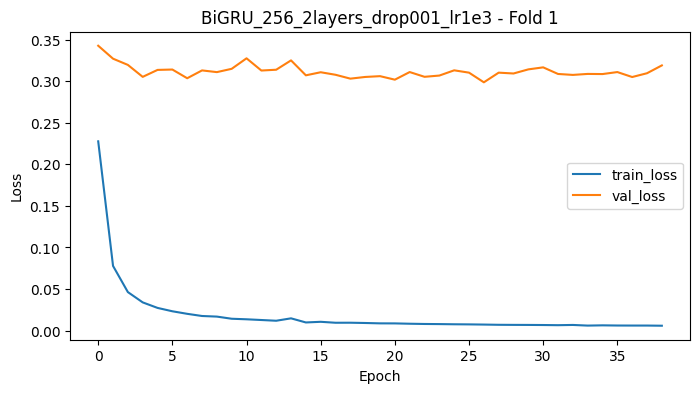

In [114]:
def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.show()


champion_histories = all_histories[champion_variant]
plot_history(champion_histories[0], f"{champion_variant} - Fold 1")

### Per-joint evaluation in centimeters

In [115]:
champion_fold_df = results_folds[results_folds["model_variant"] == champion_variant].copy()

joint_cols = [f"{joint}_dist_cm" for joint in JOINTS]
joint_summary = champion_fold_df[joint_cols].mean().sort_values()

display(joint_summary.to_frame("mean_distance_cm"))

,mean_distance_cm
right_hip_dist_cm,0.927000
left_hip_dist_cm,0.935617
right_shoulder_dist_cm,2.585016
left_shoulder_dist_cm,2.866683
head_dist_cm,3.802895
right_elbow_dist_cm,6.391766
left_elbow_dist_cm,6.705889
right_knee_dist_cm,8.193989
left_knee_dist_cm,8.216601
left_foot_dist_cm,9.544763


### Save result tables

In [116]:
fold_results_path = output_dir / "A10_posenet_to_kinect2d_folds.csv"
summary_results_path = output_dir / "A10_posenet_to_kinect2d_summary.csv"

results_folds.to_csv(fold_results_path, index=False)
results_summary.to_csv(summary_results_path, index=False)

print("Saved fold results to:", fold_results_path)
print("Saved summary results to:", summary_results_path)

Saved fold results to: reporting\results\A10_posenet_to_kinect2d_folds.csv
Saved summary results to: reporting\results\A10_posenet_to_kinect2d_summary.csv


### Optimizing the champion model

### Retrain the champion model on almost all data

In [117]:

champion_config = next(cfg for cfg in experiment_configs if cfg["model_variant"] == champion_variant)

unique_seq_ids = np.unique(seq_ids)
train_seq_ids, val_seq_ids = train_test_split(
    unique_seq_ids,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

train_mask = np.isin(seq_ids, train_seq_ids)
val_mask = np.isin(seq_ids, val_seq_ids)

X_train_final = X[train_mask]
y_train_final = y[train_mask]
X_val_final = X[val_mask]
y_val_final = y[val_mask]

if USE_MIRROR_AUGMENTATION:
    X_train_final_mirror, _ = mirror_sequence_features(X_train_final, POSE_NO_PREFIX, x_center=None)
    y_train_final_mirror, _ = mirror_sequence_features(y_train_final, KINECT_NO_PREFIX, x_center=None)

    X_train_final = np.concatenate([X_train_final, X_train_final_mirror], axis=0)
    y_train_final = np.concatenate([y_train_final, y_train_final_mirror], axis=0)

x_scaler_final = fit_scaler_on_training_sequences(X_train_final)
y_scaler_final = fit_scaler_on_training_sequences(y_train_final)

X_train_final_scaled = transform_sequences(X_train_final, x_scaler_final)
X_val_final_scaled = transform_sequences(X_val_final, x_scaler_final)

y_train_final_scaled = transform_sequences(y_train_final, y_scaler_final)
y_val_final_scaled = transform_sequences(y_val_final, y_scaler_final)


In [119]:
# Pick champion from tuning round if it exists, otherwise from the regular summary
if "tuned_champion_variant" in globals():
    final_champion_variant = tuned_champion_variant
    final_champion_family = tuned_champion_family
    final_champion_row = tuned_champion_row
    config_pool = gru_tuning_configs if "gru_tuning_configs" in globals() else experiment_configs
else:
    final_champion_variant = champion_variant
    final_champion_family = champion_family
    final_champion_row = champion_row
    config_pool = experiment_configs

champion_config = next(cfg for cfg in config_pool if cfg["model_variant"] == final_champion_variant)

print("Final champion family:", final_champion_family)
print("Final champion variant:", final_champion_variant)
print("Champion config:", champion_config)

unique_seq_ids = np.unique(seq_ids)
train_seq_ids, val_seq_ids = train_test_split(
    unique_seq_ids,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

train_mask = np.isin(seq_ids, train_seq_ids)
val_mask = np.isin(seq_ids, val_seq_ids)

X_train_final = X[train_mask]
y_train_final = y[train_mask]
X_val_final = X[val_mask]
y_val_final = y[val_mask]

# Mirror only the final training split
if USE_MIRROR_AUGMENTATION:
    X_train_final_mirror, _ = mirror_sequence_features(X_train_final, POSE_NO_PREFIX, x_center=None)
    y_train_final_mirror, _ = mirror_sequence_features(y_train_final, KINECT_NO_PREFIX, x_center=None)

    X_train_final = np.concatenate([X_train_final, X_train_final_mirror], axis=0)
    y_train_final = np.concatenate([y_train_final, y_train_final_mirror], axis=0)

x_scaler_final = fit_scaler_on_training_sequences(X_train_final)
y_scaler_final = fit_scaler_on_training_sequences(y_train_final)

X_train_final_scaled = transform_sequences(X_train_final, x_scaler_final)
X_val_final_scaled = transform_sequences(X_val_final, x_scaler_final)

y_train_final_scaled = transform_sequences(y_train_final, y_scaler_final)
y_val_final_scaled = transform_sequences(y_val_final, y_scaler_final)

train_loader_final = DataLoader(
    SequenceDataset(X_train_final_scaled, y_train_final_scaled),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

val_loader_final = DataLoader(
    SequenceDataset(X_val_final_scaled, y_val_final_scaled),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

final_model = build_model(final_champion_family, champion_config)

print("Final train sequences:", len(X_train_final))
print("Final val sequences:", len(X_val_final))
print("Final model created:", type(final_model).__name__)

Final champion family: GRU
Final champion variant: BiGRU_256_2layers_drop001_lr1e3
Champion config: {'model_family': 'GRU', 'model_variant': 'BiGRU_256_2layers_drop001_lr1e3', 'hidden_size': 256, 'num_layers': 2, 'dropout_rate': 0.01, 'bidirectional': True, 'learning_rate': 0.001}
Final train sequences: 37114
Final val sequences: 2047
Final model created: GRUPoseNetToKinectRegressor


### Train and save the champion model

In [121]:
final_lr = champion_config.get("learning_rate", LEARNING_RATE)

with mlflow.start_run(run_name=f"{final_champion_variant}_final", nested=False):
    mlflow.log_param("final_model_family", final_champion_family)
    mlflow.log_param("final_model_variant", final_champion_variant)
    mlflow.log_param("final_learning_rate", final_lr)

    final_model, final_history, final_best_val_loss, final_best_epoch = train_model(
        model=final_model,
        train_loader=train_loader_final,
        val_loader=val_loader_final,
        optimizer_name=DEFAULT_OPTIMIZER,
        lr=final_lr,
        epochs=EPOCHS,
        patience=PATIENCE,
    )

    mlflow.log_metric("final_best_val_loss", float(final_best_val_loss))
    mlflow.log_metric("final_best_epoch", int(final_best_epoch))

    final_model_path = artifact_dir / "A10_champion_model.pt"
    final_x_scaler_path = artifact_dir / "A10_x_scaler.npz"
    final_y_scaler_path = artifact_dir / "A10_y_scaler.npz"
    final_metadata_path = artifact_dir / "A10_champion_metadata.json"

    torch.save(final_model.state_dict(), final_model_path)

    np.savez(final_x_scaler_path, mean=x_scaler_final.mean_, scale=x_scaler_final.scale_)
    np.savez(final_y_scaler_path, mean=y_scaler_final.mean_, scale=y_scaler_final.scale_)

    metadata = {
        "model_family": final_champion_family,
        "model_variant": final_champion_variant,
        "sequence_length": SEQ_LEN,
        "input_features": INPUT_FEATURES,
        "target_features": TARGET_FEATURES,
        "target_unit": TARGET_UNIT,
        "mean_cv_test_mae": float(final_champion_row["mean_test_mae"]),
        "mean_cv_test_mae_cm": float(final_champion_row["mean_test_mae_cm"]),
        "std_cv_test_mae_cm": float(final_champion_row["std_test_mae_cm"]),
        "mean_cv_avg_2d_dist_cm": float(final_champion_row["mean_avg_2d_dist_cm"]),
        "std_cv_avg_2d_dist_cm": float(final_champion_row["std_avg_2d_dist_cm"]),
        "best_epoch_final": int(final_best_epoch),
        "device": str(DEVICE),
        "config": {k: list(v) if isinstance(v, tuple) else v for k, v in champion_config.items()},
    }

    with open(final_metadata_path, "w") as f:
        json.dump(metadata, f, indent=2)

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_x_scaler_path))
    mlflow.log_artifact(str(final_y_scaler_path))
    mlflow.log_artifact(str(final_metadata_path))

print("Saved champion model to:", final_model_path)
print("Saved X scaler to:", final_x_scaler_path)
print("Saved Y scaler to:", final_y_scaler_path)
print("Saved metadata to:", final_metadata_path)

🏃 View run BiGRU_256_2layers_drop001_lr1e3_final at: https://172.27.62.170:5001/#/experiments/26/runs/e15ab903f9e64f59a4c8c4ca363cac6e
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/26
Saved champion model to: reporting\artifacts\A10_champion_model.pt
Saved X scaler to: reporting\artifacts\A10_x_scaler.npz
Saved Y scaler to: reporting\artifacts\A10_y_scaler.npz
Saved metadata to: reporting\artifacts\A10_champion_metadata.json


### Reload the saved champion model

In [123]:
def load_saved_scaler(npz_path):
    data = np.load(npz_path)
    scaler = StandardScaler()
    scaler.mean_ = data["mean"]
    scaler.scale_ = data["scale"]
    scaler.var_ = scaler.scale_ ** 2
    scaler.n_features_in_ = len(scaler.mean_)
    return scaler

with open(final_metadata_path, "r") as f:
    loaded_meta = json.load(f)

loaded_config = loaded_meta["config"]
if "hidden_units" in loaded_config and isinstance(loaded_config["hidden_units"], list):
    loaded_config["hidden_units"] = tuple(loaded_config["hidden_units"])
if "filters" in loaded_config and isinstance(loaded_config["filters"], list):
    loaded_config["filters"] = tuple(loaded_config["filters"])
if "channels" in loaded_config and isinstance(loaded_config["channels"], list):
    loaded_config["channels"] = tuple(loaded_config["channels"])

loaded_model = build_model(loaded_meta["model_family"], loaded_config)
loaded_model.load_state_dict(torch.load(final_model_path, map_location=DEVICE))
loaded_model.to(DEVICE)
loaded_model.eval()

loaded_x_scaler = load_saved_scaler(final_x_scaler_path)
loaded_y_scaler = load_saved_scaler(final_y_scaler_path)

print("Loaded model:", loaded_meta["model_variant"])

Loaded model: BiGRU_256_2layers_drop001_lr1e3


### Quick prediction check

In [124]:
X_sample = X[:5]
y_sample = y[:5]

X_sample_scaled = transform_sequences(X_sample, loaded_x_scaler)
y_sample_scaled = transform_sequences(y_sample, loaded_y_scaler)

sample_ds = SequenceDataset(X_sample_scaled, y_sample_scaled)
sample_loader = DataLoader(sample_ds, batch_size=5, shuffle=False)

y_true_scaled, y_pred_scaled = predict_model(loaded_model, sample_loader)

y_true_sample = inverse_transform_sequences(y_true_scaled, loaded_y_scaler)
y_pred_sample = inverse_transform_sequences(y_pred_scaled, loaded_y_scaler)

sample_mae = mean_absolute_error(
    y_true_sample.reshape(-1, y_true_sample.shape[-1]),
    y_pred_sample.reshape(-1, y_pred_sample.shape[-1]),
)

sample_avg_2d_dist = mean_2d_distance(y_true_sample, y_pred_sample)

print("Sample MAE:", sample_mae)
print("Sample MAE (cm):", to_cm(sample_mae))
print("Sample average 2D distance (cm):", to_cm(sample_avg_2d_dist))

Sample MAE: 0.008044211
Sample MAE (cm): 0.8044211193919182
Sample average 2D distance (cm): 1.3760531321167946
